# 1124 Pre-main experiment | distance × internal representation
探索的な本実験リハーサル。50組の独立Probe評価v5の通過33組から、10カテゴリーにつき1組を事前固定。240 Cue、500入力、Avoid X/Neutral X。Probe L22–24、Logit Lens L1–24、生成各1回（補助）。結果方向で刺激・対象・指標を再選定しない。

**Colab GPU (T4以上)**。Secrets: OPENAI_API_KEY, GITHUB_RESULTS_TOKEN (Contents read/write)。上から実行。候補生成・推論チェックポイントをGitHubに保存するため中断再開可能。再実行時は同一RUN_IDの設定・入力を変えない。変更時は新RUN_ID。人手監査は未実施、結果は探索的。



In [1]:
%pip -q install "transformers==4.57.6" "accelerate>=1,<2" "huggingface-hub>=0.30,<1" "scikit-learn==1.6.1" "sentence-transformers>=3,<6" "openai>=1.70,<3" pandas numpy scipy requests tqdm matplotlib tabulate



ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, io, json, re, hashlib, base64, time, math, random, unicodedata, warnings
from pathlib import Path
from datetime import datetime, timezone
from difflib import SequenceMatcher
import numpy as np, pandas as pd, torch, requests
import torch.nn.functional as F
from tqdm.auto import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.stats import linregress, spearmanr
from transformers import AutoTokenizer, AutoModelForCausalLM
from sentence_transformers import SentenceTransformer
from openai import OpenAI
from google.colab import userdata
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

REPO="ryouy/GraduationThesis"
SOURCE_SHA="a9095b153ff869556bcf3fbba4dddee6a43b305a"
SOURCE="experiments/2026-11/1124_probe_50pairs/results/20261124_probe50_balanced_v5"
ROOT="experiments/2026-11/1124_pre_main_experiment"
RUN_ID="20261124_pre_main_v1"
DEST=f"{ROOT}/results/{RUN_ID}"
WORK=Path("/content/pre_main_experiment")/RUN_ID
WORK.mkdir(parents=True,exist_ok=True)
MODEL="Qwen/Qwen2.5-0.5B-Instruct"
REV="7ae557604adf67be50417f59c2c2f167def9a775"
EMBED_MODEL="sentence-transformers/all-mpnet-base-v2"
EMBED_REV="e8c3b32edf5434bc2275fc9bab85f82640a19130"
API_MODEL="gpt-4o-mini"
SEED=42
LAYERS=[22,23,24]
STYLES=["structure","action","situation","function"]
BANDS=["very_near","near","medium_near","medium_far","far"]
CONDS=["Avoid X","Neutral X"]
SELECTED=["C01","C06","C12","C16","C25","C27","C35","C38","C42","C46"]
GEN_SEED=101
CHUNK=10
PUBLISH=True
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
def secret(name):
    try: value=userdata.get(name)
    except Exception: value=None
    if not value: raise RuntimeError("Set Colab Secret: "+name)
    return value
assert torch.cuda.is_available(),"Select GPU in Colab"
GH_TOKEN=secret("GITHUB_RESULTS_TOKEN")
client=OpenAI(api_key=secret("OPENAI_API_KEY"),timeout=120,max_retries=3)
gh=requests.Session()
gh.headers.update({"Authorization":"Bearer "+GH_TOKEN,"Accept":"application/vnd.github+json","X-GitHub-Api-Version":"2022-11-28"})
API=f"https://api.github.com/repos/{REPO}/contents/"
def sha(b):return hashlib.sha256(b).hexdigest()
def dump(o):return (json.dumps(o,sort_keys=True,ensure_ascii=False,indent=2,allow_nan=False)+"\n").encode()
def get(path,ref=None):
    r=gh.get(API+path,params={"ref":ref} if ref else {},timeout=90)
    if r.status_code==404:return None
    r.raise_for_status(); info=r.json()
    if info.get("encoding")=="base64":return base64.b64decode(info["content"])
    r=gh.get(info["download_url"],timeout=180);r.raise_for_status();return r.content
def put(path,b):
    # Existing artifacts are never overwritten. Use Git blob identity, not CSV text reserialization.
    r=gh.get(API+path,timeout=90)
    if r.status_code==200:
        assert r.json()["sha"]==hashlib.sha1(b"blob "+str(len(b)).encode()+b"\0"+b).hexdigest(), "Immutable artifact conflict: "+path
        return
    assert r.status_code==404, (r.status_code,r.text[:300])
    r=gh.put(API+path,json={"branch":"main","message":"Pre-main: "+path.rsplit("/",1)[-1],
        "content":base64.b64encode(b).decode()},timeout=180)
    r.raise_for_status()
def save(name,b,remote=True):
    p=WORK/name;p.parent.mkdir(parents=True,exist_ok=True);p.write_bytes(b)
    if remote and PUBLISH:put(f"{DEST}/{name}",b)
def source_file(name):
    b=get(f"{SOURCE}/{name}",SOURCE_SHA)
    if b is None:raise FileNotFoundError(name)
    return b
def frame(b):return pd.read_csv(io.BytesIO(b),float_precision="round_trip")
def save_frame(name,df,remote=True):save(name,df.to_csv(index=False).encode(),remote)
print("GPU",torch.cuda.get_device_name(0),"source commit",SOURCE_SHA)



GPU Tesla T4 source commit a9095b153ff869556bcf3fbba4dddee6a43b305a


## 1. 選定・Probeの復元
先の提案10組を固定（成績順に事後再選定しない）。v5の全50候補と通過判定を確認。保存済み学習Hidden Stateから同一のStandardScaler＋LogisticRegressionを再構築し、独立評価AUCの一致を全3層で検査する。



In [3]:
scores_raw=source_file("pair_probe_scores.csv")
manifest_raw=source_file("manifest.json")
src_manifest=json.loads(manifest_raw)
scores=frame(scores_raw)
assert len(scores)==50 and scores.candidate_id.is_unique
passed=scores[(scores.L24_auc>=.8)&(scores.fdr_q<=.05)]
assert len(passed)==33
pairs=scores.set_index("candidate_id").loc[SELECTED].reset_index()
assert len(pairs)==10 and pairs.category.nunique()==10
assert (pairs.L24_auc>=.8).all() and (pairs.fdr_q<=.05).all()
params=src_manifest["parameters"]
assert params["revision"]==REV and params["model"]==MODEL and params["layers"]==LAYERS
assert params["probe_C"]==.1 and params["seed"]==SEED
assert params["per_class"]==8 and params["batch_size"]==24
config=dict(run_id=RUN_ID,source_commit=SOURCE_SHA,source_scores_sha256=sha(scores_raw),
    source_manifest_sha256=sha(manifest_raw),selected=SELECTED,model=MODEL,revision=REV,
    embedding_model=EMBED_MODEL,embedding_revision=EMBED_REV,api_model=API_MODEL,
    seed=SEED,styles=STYLES,bands=BANDS,conditions=CONDS,candidates_per_style_per_band=3,
    unrelated_candidates_per_style=2,related_per_band=4,unrelated_per_concept=4,
    n_generations=1,temperature=.7,top_p=.9,max_new_tokens=128,gen_seed=GEN_SEED,
    probe_layers=LAYERS,lens_layers=list(range(1,25)),chunk_size=CHUNK,
    cue_selection="global empirical distance quintiles, one candidate per style where feasible",
    prompt_template_version="pilot_avoid_neutral_v1",cue_generation_version="style_split_fixed_definitions_v1",analysis="exploratory")
save("config.json",dump(config));save_frame("selected_pairs.csv",pairs)
display(pairs[["category","target_x","comparator_y","L24_auc","L24_loo_min","fdr_q"]])
text_raw=source_file("balanced_descriptions.csv")
assert sha(text_raw)==src_manifest["input_sha256"],"Source descriptions hash mismatch"
texts=frame(text_raw)
assert len(texts)==1312
names=set(pairs.target_x)|set(pairs.comparator_y)
need=np.flatnonzero(texts.concept.isin(names).to_numpy())
batch_size=params["batch_size"]
vectors={}
for b in tqdm(sorted(set(need//batch_size)),desc="Restore saved Probe features"):
    raw=source_file(f"features/chunk_{b:03d}.npz")
    with np.load(io.BytesIO(raw),allow_pickle=False) as f:
        start,end=int(f["begin"]),int(f["end"])
        assert start==b*batch_size and end==min(len(texts),(b+1)*batch_size)
        assert str(f["input_hash"])==sha(text_raw) and f["layers"].tolist()==LAYERS
        arr=f["features"]
        assert arr.shape==(end-start,3,896) and np.isfinite(arr).all()
        for i in range(start,end):
            if texts.iloc[i].concept in names:vectors[i]=arr[i-start].copy()
assert set(vectors)==set(need)
idx={(r.concept,r.split,int(r.family)):i for i,r in enumerate(texts.itertuples()) if i in vectors}
def vec(name,split,li):return np.stack([vectors[idx[name,split,i]][li] for i in range(8)])
PROBES={};checks=[];weights={}
for p in pairs.itertuples():
    for li,l in enumerate(LAYERS):
        a,b=vec(p.target_x,"train",li),vec(p.comparator_y,"train",li)
        ea,eb=vec(p.target_x,"eval",li),vec(p.comparator_y,"eval",li)
        labels=np.r_[np.ones(8,dtype=int),np.zeros(8,dtype=int)]
        train=np.concatenate([a,b]);test=np.concatenate([ea,eb])
        ss=StandardScaler().fit(train)
        clf=LogisticRegression(C=.1,solver="liblinear",max_iter=1000,random_state=SEED).fit(ss.transform(train),labels)
        auc=roc_auc_score(labels,clf.decision_function(ss.transform(test)))
        expected=getattr(p,f"L{l}_auc")
        assert abs(auc-expected)<1e-9,(p.target_x,l,auc,expected)
        PROBES[p.target_x,l]=(ss,clf)
        checks.append(dict(target_x=p.target_x,layer=l,restored_auc=auc,source_auc=expected))
        weights[f"{p.target_x}|{l}"]=dict(mean=ss.mean_.tolist(),scale=ss.scale_.tolist(),
            coef=clf.coef_[0].tolist(),intercept=float(clf.intercept_[0]))
save_frame("probe_reconstruction.csv",pd.DataFrame(checks))
save("probe_weights.json",dump(weights))
print("Verified 30 restored Probes against v5 independent AUCs.")



,category,target_x,comparator_y,L24_auc,L24_loo_min,fdr_q
0,vehicles,bicycle,submarine,1.000000,1.000000,0.011111
1,land_mammals,elephant,lion,1.000000,0.937500,0.011111
2,marine_animals,jellyfish,octopus,1.000000,0.937500,0.011111
3,insects,ant,dragonfly,1.000000,0.968750,0.015000
4,musical_instruments,drum,tambourine,0.984375,0.890625,0.011111
5,fruits,banana,pineapple,0.937500,0.875000,0.018519
6,furniture,bookshelf,cabinet,0.890625,0.843750,0.018519
7,tools,scissors,pliers,0.968750,0.921875,0.011111
8,plants,cactus,aloe,1.000000,1.000000,0.017391
9,natural_phenomena,rain,snow,0.984375,0.968750,0.011111


Restore saved Probe features:   0%|          | 0/20 [00:00<?, ?it/s]

Verified 30 restored Probes against v5 independent AUCs.


## 2. 新規Cue候補の生成・固定
各Xに対し関連60候補（4文章タイプ×5想定距離×3）と無関係8候補を作る。AIによる想定距離は候補の多様性を確保するためだけに使い、採択の距離帯は実測値から決定する。対象と比較概念の定義は事前作成した短い英文を各1文固定（人手独立評価なし）。生成は文章タイプ単位でチェックポイント化。X/Yの名称・明白な別名を避け、学習・独立評価文との表層重複を点検。自動検査は人手監査を代替しない。



In [10]:

import time
import random
import json
import hashlib
import base64
import requests

MAX_GITHUB_RETRIES = 15
MAX_CALLS_PER_BAND = 30


# ==================================================
# 1. GitHub通信・書き込みの自動再試行
# ==================================================

def retryable(response):

    if response.status_code in (
        408, 409, 429, 500, 502, 503, 504
    ):
        return True

    if response.status_code == 403:
        return (
            response.headers.get(
                "X-RateLimit-Remaining"
            ) == "0"
            or "Retry-After" in response.headers
            or "rate limit" in response.text.lower()
        )

    return False


def retry_wait(attempt, response=None):

    wait = min(2 ** attempt, 60) + random.random()

    if response is not None:

        retry_after = response.headers.get("Retry-After")

        if retry_after and retry_after.isdigit():
            wait = max(wait, int(retry_after))

        if response.headers.get(
            "X-RateLimit-Remaining"
        ) == "0":

            reset = response.headers.get(
                "X-RateLimit-Reset"
            )

            if reset and reset.isdigit():
                wait = max(
                    wait,
                    int(reset) - time.time() + 2
                )

    tqdm.write(
        f"[GitHub RETRY] "
        f"attempt={attempt + 1} "
        f"wait={wait:.1f}s"
    )

    time.sleep(wait)


def get(path, ref=None):

    for attempt in range(MAX_GITHUB_RETRIES):

        try:

            r = gh.get(
                API + path,
                params={"ref": ref} if ref else {},
                timeout=90
            )

            if r.status_code == 404:
                return None

            if retryable(r):
                retry_wait(attempt, r)
                continue

            r.raise_for_status()

            info = r.json()

            if info.get("encoding") == "base64":
                return base64.b64decode(
                    info["content"]
                )

            r = gh.get(
                info["download_url"],
                timeout=180
            )

            if retryable(r):
                retry_wait(attempt, r)
                continue

            r.raise_for_status()

            return r.content

        except (
            requests.ConnectionError,
            requests.Timeout
        ):

            retry_wait(attempt)

    raise RuntimeError(
        f"GitHub read retry limit exceeded: {path}"
    )


def put(path, b):

    expected_sha = hashlib.sha1(
        b"blob "
        + str(len(b)).encode()
        + b"\0"
        + b
    ).hexdigest()

    payload = {
        "branch": "main",
        "message": (
            "Pre-main: " + path.rsplit("/", 1)[-1]
        ),
        "content": base64.b64encode(b).decode()
    }

    for attempt in range(MAX_GITHUB_RETRIES):

        try:

            r = gh.get(
                API + path,
                params={"ref": "main"},
                timeout=90
            )

            if r.status_code == 200:

                if r.json()["sha"] == expected_sha:
                    return

                raise RuntimeError(
                    f"Immutable artifact conflict: {path}"
                )

            if retryable(r):
                retry_wait(attempt, r)
                continue

            if r.status_code != 404:
                r.raise_for_status()

            r = gh.put(
                API + path,
                json=payload,
                timeout=180
            )

            if r.status_code in (200, 201):

                time.sleep(1.0)
                return

            if retryable(r):

                tqdm.write(
                    f"[GitHub HTTP {r.status_code}] "
                    f"{path.rsplit('/', 1)[-1]}"
                )

                retry_wait(attempt, r)
                continue

            r.raise_for_status()

        except (
            requests.ConnectionError,
            requests.Timeout
        ):

            retry_wait(attempt)

    raise RuntimeError(
        f"GitHub write retry limit exceeded: {path}"
    )


# ==================================================
# 2. ローカル保存・チェックポイントの復元
# ==================================================

def save(name, b, remote=True):

    local = WORK / name

    local.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # GitHubへの書き込み前にローカル保存
    local.write_bytes(b)

    if remote and PUBLISH:
        put(f"{DEST}/{name}", b)


def recover_checkpoint(name):

    raw = get(f"{DEST}/{name}")
    local = WORK / name

    # GitHubに存在する場合
    if raw is not None:

        if local.exists():

            if local.read_bytes() != raw:
                raise RuntimeError(
                    f"Local/remote mismatch: {name}"
                )

        save(name, raw, False)

        return raw, False

    # GitHub保存に失敗したローカルデータ
    if local.exists():

        tqdm.write(
            f"[LOCAL RECOVERY] {name}"
        )

        return local.read_bytes(), True

    return None, False


# ==================================================
# 3. Cue逐次生成のJSONスキーマ
# ==================================================

recovery_schema = {
    "name": "cue_recovery",
    "strict": True,
    "schema": {
        "type": "object",
        "properties": {
            "sentences": {
                "type": "array",
                "items": {
                    "type": "string"
                }
            }
        },
        "required": ["sentences"],
        "additionalProperties": False
    }
}

RELATEDNESS = {
    "very_near":
        "Direct distinctive association",
    "near":
        "Strong semantic association",
    "medium_near":
        "Moderate semantic association",
    "medium_far":
        "Indirect semantic association",
    "far":
        "Weak but plausible association",
    "unrelated":
        "No plausible association to X or Y"
}


# ==================================================
# 4. Cue生成
# ==================================================

def make_bank(p):

    all_rows = []
    seen = []

    prior = texts.loc[
        texts.concept.isin([
            p.target_x,
            p.comparator_y
        ]),
        "user_prompt"
    ].tolist()

    for style in STYLES:

        name = (
            f"cue_style_checkpoints/"
            f"{p.candidate_id}_{style}.json"
        )

        cached, needs_upload = recover_checkpoint(name)

        # 完了済み文章タイプの復元
        if cached is not None:

            obj = json.loads(cached)

            current = validate_style(
                obj, p, style, seen
            )

            if needs_upload:
                save(name, cached)

            tqdm.write(
                f"[CACHED] {p.target_x} / {style}"
            )

        else:

            obj = {}
            current = []

            for band in BANDS + ["unrelated"]:

                required = (
                    2 if band == "unrelated" else 3
                )

                accepted = []
                attempt = 0

                band_path = (
                    f"cue_band_checkpoints/"
                    f"{p.candidate_id}_{style}_{band}.json"
                )

                cached_band, needs_band_upload = (
                    recover_checkpoint(band_path)
                )

                def valid_sentence(s):

                    if not isinstance(s, str):
                        return False

                    if not 6 <= len(s.split()) <= 35:
                        return False

                    if "\n" in s:
                        return False

                    if any(
                        label_hit(s, label)
                        for label in forbidden(
                            p.target_x,
                            p.comparator_y
                        )
                    ):
                        return False

                    if any(
                        sim(s, old) >= .85
                        for old in (
                            seen
                            + prior
                            + current
                            + accepted
                        )
                    ):
                        return False

                    return True

                # 保存済み距離帯を復元
                if cached_band is not None:

                    recovered = json.loads(
                        cached_band
                    )

                    assert len(recovered) == required

                    for sentence in recovered:

                        assert valid_sentence(
                            sentence
                        ), sentence

                        accepted.append(sentence)

                    if needs_band_upload:
                        save(
                            band_path,
                            cached_band
                        )

                    tqdm.write(
                        f"[CACHED BAND] "
                        f"{p.target_x} / {style} / {band}"
                    )

                # 不足分だけ生成
                while len(accepted) < required:

                    attempt += 1

                    if attempt > MAX_CALLS_PER_BAND:

                        raise RuntimeError(
                            f"Retry budget exceeded: "
                            f"{p.target_x}/{style}/{band}"
                        )

                    missing = required - len(accepted)

                    ask = f"""
Target concept X: {p.target_x}
Comparison concept Y: {p.comparator_y}

Definition X:
{DEFINITIONS[p.target_x]}

Definition Y:
{DEFINITIONS[p.comparator_y]}

Sentence style:
{style}: {STYLE_DESC[style]}

Semantic relatedness:
{RELATEDNESS[band]}

Generate exactly {missing} new English clue sentence(s).

Requirements:
- Natural, factual, self-contained sentences.
- Ideally 10-20 words per sentence.
- Never explicitly name X or Y.
- Avoid obvious aliases and spelling variants.
- Avoid intentionally Y-specific related clues.
- Do not repeat existing sentences or facts.
- Keep sentence style and length comparable.

Forbidden terms:
{forbidden(p.target_x, p.comparator_y)}

Previously generated sentences:
{json.dumps(seen + current + accepted)}

Existing Probe descriptions:
{json.dumps(prior)}
"""

                    # OpenAI API通信エラーへの対応
                    try:

                        response = client.chat.completions.create(
                            model=API_MODEL,
                            temperature=0.6,
                            max_completion_tokens=1000,
                            response_format={
                                "type": "json_schema",
                                "json_schema": recovery_schema
                            },
                            messages=[
                                {
                                    "role": "system",
                                    "content": (
                                        "Generate natural English "
                                        "clues according to the "
                                        "specified requirements."
                                    )
                                },
                                {
                                    "role": "user",
                                    "content": ask
                                }
                            ]
                        )

                    except Exception as e:

                        status = getattr(
                            e, "status_code", None
                        )

                        transient = (
                            status in (
                                408, 409, 429,
                                500, 502, 503, 504
                            )
                            or type(e).__name__ in (
                                "APIConnectionError",
                                "APITimeoutError"
                            )
                        )

                        if not transient:
                            raise

                        if getattr(e, "code", None) == (
                            "insufficient_quota"
                        ):
                            raise

                        wait = min(
                            2 ** attempt, 60
                        )

                        tqdm.write(
                            f"[OpenAI RETRY] "
                            f"{type(e).__name__} "
                            f"wait={wait}s"
                        )

                        time.sleep(wait)
                        continue

                    try:

                        result = json.loads(
                            response.choices[0]
                            .message.content or "{}"
                        )

                        sentences = result.get(
                            "sentences", []
                        )

                        if not isinstance(sentences, list):
                            sentences = []

                    except (
                        ValueError,
                        TypeError,
                        AttributeError
                    ):

                        sentences = []

                    before = len(accepted)

                    for sentence in sentences:

                        if len(accepted) >= required:
                            break

                        if valid_sentence(sentence):
                            accepted.append(sentence)

                    tqdm.write(
                        f"[GENERATING] {p.target_x}"
                        f" / {style} / {band}"
                        f" : {len(accepted)}/{required}"
                        f" | attempt {attempt}"
                    )

                    if len(accepted) == before:

                        time.sleep(
                            min(attempt * 2, 15)
                        )

                # 距離帯完了時に保存
                # 409が発生しても同じデータで再試行
                if cached_band is None:

                    save(
                        band_path,
                        dump(accepted)
                    )

                obj[band] = accepted
                current.extend(accepted)

            # 従来の品質基準で再検証
            current = validate_style(
                obj, p, style, seen
            )

            save(name, dump(obj))

        seen.extend(current)

        all_rows.extend(
            {
                "style": style,
                "intended_band": band,
                "text": sentence
            }
            for band in BANDS + ["unrelated"]
            for sentence in obj[band]
        )

        tqdm.write(
            f"[STYLE COMPLETE] "
            f"{p.target_x} / {style}"
        )

    d = {
        "definition_x": DEFINITIONS[p.target_x],
        "definition_y": DEFINITIONS[p.comparator_y],
        "cues": all_rows
    }

    validate_bank(d, p)

    return d


# ==================================================
# 5. 変更履歴
# ==================================================

save(
    "cue_recovery_method_v2.json",
    dump({
        "method": "incremental_band_generation",
        "preserve_existing_checkpoints": True,
        "validation_thresholds_changed": False,
        "max_calls_per_band": MAX_CALLS_PER_BAND,
        "github_max_retries": MAX_GITHUB_RETRIES,
        "github_conflict_retry": True,
        "local_checkpoint_recovery": True,
        "openai_transient_error_retry": True
    })
)


# ==================================================
# 6. 全概念の生成・復元
# ==================================================

banks = {}

for p in tqdm(
    pairs.itertuples(),
    total=len(pairs),
    desc="Generate/recover cue banks"
):

    name = f"cue_banks/{p.candidate_id}.json"

    raw, needs_upload = recover_checkpoint(name)

    if raw is None:

        d = make_bank(p)

        raw = dump(d)

        save(name, raw)

    else:

        d = json.loads(raw)

        validate_bank(d, p)

        if needs_upload:
            save(name, raw)

    banks[p.candidate_id] = d

    tqdm.write(
        f"[COMPLETED] {p.target_x}"
        f" ({len(banks)}/{len(pairs)})"
    )


# ==================================================
# 7. 最終検証
# ==================================================

assert len(banks) == len(pairs)

total_cues = sum(
    len(d["cues"]) for d in banks.values()
)

assert total_cues == len(pairs) * 68

print("=" * 60)
print("All cue banks successfully generated.")
print("Completed concepts:", len(banks))
print("Total candidate cues:", total_cues)
print("=" * 60)


Generate/recover cue banks:   0%|          | 0/10 [00:00<?, ?it/s]

[COMPLETED] bicycle (1/10)
[COMPLETED] elephant (2/10)
[COMPLETED] jellyfish (3/10)
[COMPLETED] ant (4/10)
[COMPLETED] drum (5/10)
[COMPLETED] banana (6/10)
[LOCAL RECOVERY] cue_band_checkpoints/C35_structure_very_near.json
[CACHED BAND] bookshelf / structure / very_near
[GENERATING] bookshelf / structure / near : 3/3 | attempt 1
[GENERATING] bookshelf / structure / medium_near : 3/3 | attempt 1
[GENERATING] bookshelf / structure / medium_far : 3/3 | attempt 1
[GENERATING] bookshelf / structure / far : 3/3 | attempt 1
[GENERATING] bookshelf / structure / unrelated : 2/2 | attempt 1
[STYLE COMPLETE] bookshelf / structure
[GENERATING] bookshelf / action / very_near : 3/3 | attempt 1
[GENERATING] bookshelf / action / near : 3/3 | attempt 1
[GENERATING] bookshelf / action / medium_near : 3/3 | attempt 1
[GENERATING] bookshelf / action / medium_far : 3/3 | attempt 1
[GENERATING] bookshelf / action / far : 3/3 | attempt 1
[GENERATING] bookshelf / action / unrelated : 2/2 | attempt 1
[STYLE C

In [11]:
encoder=SentenceTransformer(EMBED_MODEL,revision=EMBED_REV,device="cpu")
candidates=[];chosen=[];quality=[];definitions=[]
for p in tqdm(pairs.itertuples(),total=len(pairs),desc="Measure distance and select"):
    d=banks[p.candidate_id]
    definitions.append(dict(candidate_id=p.candidate_id,target_x=p.target_x,comparator_y=p.comparator_y,
        definition_x=d["definition_x"],definition_y=d["definition_y"]))
    sent=[r["text"] for r in d["cues"]]
    E=encoder.encode([d["definition_x"],d["definition_y"],p.target_x,p.comparator_y]+sent,
                     normalize_embeddings=True,convert_to_numpy=True,show_progress_bar=False)
    rows=[]
    for i,r in enumerate(d["cues"]):
        rows.append(dict(candidate_id=p.candidate_id,target_x=p.target_x,comparator_y=p.comparator_y,
            cue_id=f"{p.candidate_id}_{i:03d}",cue_text=r["text"],style=r["style"],
            intended_band=r["intended_band"],distance_x=float(1-E[4+i]@E[0]),
            distance_y=float(1-E[4+i]@E[1]),distance_x_word=float(1-E[4+i]@E[2]),
            distance_y_word=float(1-E[4+i]@E[3]),word_count=len(r["text"].split())))
    g=pd.DataFrame(rows);assert np.isfinite(g[["distance_x","distance_y"]]).all().all()
    candidates.append(g)
    related=g[g.intended_band.ne("unrelated")].sort_values(["distance_x","cue_id"]).reset_index(drop=True)
    assert len(related)==60
    # Nonoverlapping global empirical quintiles, then maximize style diversity within each quintile.
    for bi,band in enumerate(BANDS):
        pool=related.iloc[bi*12:(bi+1)*12].copy()
        mid=pool.distance_x.median()
        pool["offset"]=(pool.distance_x-mid).abs()
        pool=pool.sort_values(["offset","cue_id"])
        keep=pool.drop_duplicates("style").head(4)
        if len(keep)<4:
            keep=pd.concat([keep,pool[~pool.cue_id.isin(keep.cue_id)].head(4-len(keep))])
        keep=keep.drop(columns="offset").assign(distance_band=band)
        chosen.append(keep)
        quality.append(dict(target_x=p.target_x,distance_band=band,n=len(keep),n_styles=keep["style"].nunique(),
            min_distance=keep.distance_x.min(),max_distance=keep.distance_x.max()))
    u=g[g.intended_band.eq("unrelated")].copy()
    # Unrelated controls chosen by intended semantic status, not simply most distant from X.
    u["joint_distance"]=u[["distance_x","distance_y"]].min(axis=1)
    u=u.sort_values(["joint_distance","cue_id"],ascending=[False,True]).drop_duplicates("style")
    assert len(u)==4
    chosen.append(u.drop(columns="joint_distance").assign(distance_band="unrelated"))
cue=pd.concat(chosen,ignore_index=True).sort_values(["candidate_id","cue_id"]).reset_index(drop=True)
cue["delta_x_minus_y"]=cue.distance_x-cue.distance_y
assert len(cue)==240 and cue.cue_id.is_unique
assert cue.groupby(["target_x","distance_band"]).size().eq(4).all()
for x,g in cue[cue.distance_band.ne("unrelated")].groupby("target_x"):
    bounds=g.groupby("distance_band").distance_x.agg(["min","max"]).reindex(BANDS)
    assert (bounds["max"].to_numpy()[:-1]<=bounds["min"].to_numpy()[1:]).all()
save_frame("definitions.csv",pd.DataFrame(definitions))
save_frame("cue_candidates.csv",pd.concat(candidates,ignore_index=True))
save_frame("cue_selected.csv",cue)
save_frame("cue_quality.csv",pd.DataFrame(quality))
display(pd.DataFrame(quality))
print("Selected 240 cues; all related bands separated (ties allowed). Style shortfalls are reported, not concealed.")
del encoder



/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

... (5 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Measure distance and select:   0%|          | 0/10 [00:00<?, ?it/s]

,target_x,distance_band,n,n_styles,min_distance,max_distance
0,bicycle,very_near,4,4,0.498959,0.537857
1,bicycle,near,4,4,0.629428,0.672594
2,bicycle,medium_near,4,4,0.725988,0.772142
3,bicycle,medium_far,4,4,0.844256,0.865299
4,bicycle,far,4,4,0.893782,0.918736
5,elephant,very_near,4,4,0.525926,0.608327
6,elephant,near,4,3,0.626493,0.637900
7,elephant,medium_near,4,4,0.668914,0.687988
8,elephant,medium_far,4,3,0.704526,0.716823
9,elephant,far,4,4,0.775999,0.801689


Selected 240 cues; all related bands separated (ties allowed). Style shortfalls are reported, not concealed.


## 3. 固定プロンプトとモデル
旧パイロットと同じAvoid X/Neutral X。24 CueとCueなしを2条件で実行。生成前の最後の入力トークンに対してProbeを適用。Logit Lensは旧パイロットと同じ候補系列teacher forcing、最終層のnative logitsとの一致を全入力で検査する。



In [12]:
INSTRUCTIONS={
 "Avoid X":"Do not think about {X}. Read the clue and briefly name the thing it brings to mind.",
 "Neutral X":"The word is {X}. Read the clue and briefly name the thing it brings to mind."}
rows=[]
for p in pairs.itertuples():
    cs=cue[cue.candidate_id.eq(p.candidate_id)].to_dict("records")
    cs.append(dict(cue_id="NO_CUE",cue_text="",distance_band="none",distance_x=np.nan,distance_y=np.nan,
                   word_count=0,style="none"))
    for c in cs:
        for cond in CONDS:
            tail="Clue: "+c["cue_text"]+"\nAnswer with one short phrase." if c["cue_text"] else "No clue is provided.\nAnswer with one short phrase."
            rows.append(dict(input_id=f"{p.candidate_id}__{c['cue_id']}__{cond.replace(' ','_')}",
                candidate_id=p.candidate_id,category=p.category,target_x=p.target_x,comparator_y=p.comparator_y,
                cue_id=c["cue_id"],cue_text=c["cue_text"],distance_band=c["distance_band"],
                distance_x=c["distance_x"],distance_y=c["distance_y"],word_count=c["word_count"],style=c["style"],
                condition=cond,user_prompt=INSTRUCTIONS[cond].replace("{X}",p.target_x)+"\n"+tail))
prompts=pd.DataFrame(rows).sort_values("input_id").reset_index(drop=True)
assert len(prompts)==500 and prompts.input_id.is_unique
assert prompts.groupby(["target_x","condition"]).size().eq(25).all()
prompt_raw=prompts.to_csv(index=False).encode()
save("prompts.csv",prompt_raw)
PROMPT_HASH=sha(prompt_raw)
tokenizer=AutoTokenizer.from_pretrained(MODEL,revision=REV,use_fast=True)
model=AutoModelForCausalLM.from_pretrained(MODEL,revision=REV,torch_dtype=torch.float32,
    attn_implementation="eager").to("cuda").eval()
assert model.config.num_hidden_layers==24 and model.config.hidden_size==896
EOT=sorted(set(i for i in [tokenizer.eos_token_id,tokenizer.convert_tokens_to_ids("<|im_end|>")] if isinstance(i,int) and i>=0))
def encode(text):
    return tokenizer.apply_chat_template([{"role":"user","content":text}],tokenize=True,
        add_generation_prompt=True,return_tensors="pt").to("cuda")
@torch.inference_mode()
def lens_for_label(inp,fwd,label):
    tokens=tokenizer.encode(label,add_special_tokens=False)
    assert 1<=len(tokens)<=8,(label,tokens)
    if len(tokens)==1:states=fwd.hidden_states
    else:
        app=torch.tensor([tokens[:-1]],device=inp.device,dtype=inp.dtype)
        states=model(input_ids=torch.cat([inp,app],dim=1),output_hidden_states=True,use_cache=False).hidden_states
    out=[]
    ti=torch.tensor(tokens,device=inp.device)
    for l in range(1,25):
        h=states[l][0,-len(tokens):,:]
        logits=model.lm_head(h if l==24 else model.model.norm(h)).float()
        lp=F.log_softmax(logits,dim=-1)[torch.arange(len(tokens),device=inp.device),ti]
        out.append(dict(layer=l,sequence_logprob=float(lp.sum()),mean_token_logprob=float(lp.mean()),
            token_count=len(tokens),token_ids=" ".join(map(str,tokens))))
    return out
@torch.inference_mode()
def run_input(r):
    inp=encode(r.user_prompt)
    fwd=model(input_ids=inp,output_hidden_states=True,use_cache=False)
    err=float((model.lm_head(fwd.hidden_states[-1][0,-1,:]).float()-fwd.logits[0,-1,:].float()).abs().max())
    assert err<1e-4,(r.input_id,err)
    pr=[]
    for l in LAYERS:
        ss,clf=PROBES[r.target_x,l]
        a=fwd.hidden_states[l][0,-1].float().cpu().numpy()[None,:]
        v=float(clf.decision_function(ss.transform(a))[0]);assert np.isfinite(v)
        pr.append(dict(input_id=r.input_id,layer=l,score=v))
    ls=[]
    for role,label in [("X",r.target_x),("Y",r.comparator_y)]:
        for z in lens_for_label(inp,fwd,label):
            ls.append(dict(input_id=r.input_id,candidate_role=role,candidate_text=label,**z))
    del fwd
    torch.manual_seed(GEN_SEED);torch.cuda.manual_seed_all(GEN_SEED)
    output=model.generate(input_ids=inp,do_sample=True,temperature=.7,top_p=.9,max_new_tokens=128,
        pad_token_id=tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id,
        eos_token_id=EOT,use_cache=True)
    ids=output[0,inp.shape[1]:].tolist()
    text=tokenizer.decode(ids,skip_special_tokens=True).strip()
    return dict(input_id=r.input_id,probe=pr,lens=ls,native_error=err,
        generation=dict(input_id=r.input_id,seed=GEN_SEED,response=text,
          explicit_x=label_hit(text,r.target_x),output_token_count=len(ids),
          empty_response=not bool(text),truncated_at_limit=len(ids)>=128 and (not ids or ids[-1] not in EOT)))
print("Model and frozen inputs ready.")



tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model and frozen inputs ready.


In [13]:
all_results=[]
for b in tqdm(range(math.ceil(len(prompts)/CHUNK)),desc="Inference checkpoints"):
    sub=prompts.iloc[b*CHUNK:(b+1)*CHUNK]
    name=f"checkpoints/chunk_{b:03d}.json"
    raw=get(f"{DEST}/{name}")
    if raw is None:
        results=[run_input(r) for r in sub.itertuples()]
        raw=dump(dict(prompt_hash=PROMPT_HASH,results=results))
        save(name,raw)
    else:save(name,raw,False)
    d=json.loads(raw)
    assert d["prompt_hash"]==PROMPT_HASH
    assert [r["input_id"] for r in d["results"]]==sub.input_id.tolist()
    for r in d["results"]:
        assert len(r["probe"])==3 and len(r["lens"])==48 and r["native_error"]<1e-4
        assert {z["layer"] for z in r["probe"]}==set(LAYERS)
        assert {(z["candidate_role"],z["layer"]) for z in r["lens"]}=={(role,l) for role in ["X","Y"] for l in range(1,25)}
    all_results.extend(d["results"])
assert len(all_results)==500
probe=pd.DataFrame([z for r in all_results for z in r["probe"]])
lens_raw=pd.DataFrame([z for r in all_results for z in r["lens"]])
generations=pd.DataFrame([r["generation"] for r in all_results])
assert len(probe)==1500 and len(lens_raw)==24000 and len(generations)==500
assert np.isfinite(probe.score).all() and np.isfinite(lens_raw.sequence_logprob).all()
save_frame("probe_scores.csv",probe)
save_frame("logit_lens.csv",lens_raw)
save_frame("generations.csv",generations.merge(prompts,on="input_id",validate="one_to_one"))
print("Completed",len(all_results),"inputs. Native max error",max(r["native_error"] for r in all_results))



Inference checkpoints:   0%|          | 0/50 [00:00<?, ?it/s]

Completed 500 inputs. Native max error 3.24249267578125e-05


## 4. 距離分析と可視化
Avoid Xの連続距離が主解析、Neutral Xは比較。関連20 Cue/概念・条件で記述的なOLS傾きとSpearman相関。無関係とCueなしを回帰から除く。Probe生値は概念をまたいで平均しない。出力は名称の明示的言及のみ補助指標。



In [14]:
lens=lens_raw.pivot(index=["input_id","layer"],columns="candidate_role",values="sequence_logprob").reset_index()
lens["score"]=lens.X-lens.Y
data=pd.concat([probe.assign(metric="Probe"),lens[["input_id","layer","score"]].assign(metric="Logit Lens")],ignore_index=True)
data=data.merge(prompts,on="input_id",validate="many_to_one")
related=data[data.distance_band.isin(BANDS)].copy()
assert related.groupby(["metric","target_x","condition","layer"]).size().eq(20).all()
def stats(g):
    x=g.distance_x.to_numpy();y=g.score.to_numpy()
    if np.ptp(x)==0 or np.ptp(y)==0:return dict(n=len(g),slope=np.nan,intercept=np.nan,pearson_r=np.nan,spearman_rho=np.nan)
    f=linregress(x,y)
    return dict(n=len(g),slope=f.slope,intercept=f.intercept,pearson_r=f.rvalue,spearman_rho=spearmanr(x,y).statistic)
groups=["metric","target_x","condition","layer"]
summary=pd.DataFrame([dict(zip(groups,key),**stats(g)) for key,g in related.groupby(groups)])
w=related.pivot(index=["metric","target_x","cue_id","layer","distance_x"],columns="condition",values="score").reset_index()
w["score"]=w["Avoid X"]-w["Neutral X"]
dg=["metric","target_x","layer"]
diff=pd.DataFrame([dict(zip(dg,key),**stats(g)) for key,g in w.groupby(dg)])
controls=data[~data.distance_band.isin(BANDS)].groupby(groups+["distance_band"]).score.agg(["size","mean","std"]).reset_index()
sens=[]
for key,g in related.query("layer==24").groupby(groups):
    for col in ["distance_y","word_count"]:
        rho=spearmanr(g[col],g.score).statistic if g[col].nunique()>1 else np.nan
        sens.append(dict(zip(groups,key),variable=col,spearman_rho=rho))
gen=generations.merge(prompts,on="input_id")
mention=gen.groupby(["target_x","condition","distance_band"]).explicit_x.agg(["size","sum","mean"]).reset_index()
for name,df in [("all_scores_with_distance.csv",data),("distance_statistics.csv",summary),
 ("paired_slope_difference.csv",diff),("controls_separate.csv",controls),("sensitivity_correlations.csv",pd.DataFrame(sens)),
 ("explicit_mention_by_band.csv",mention)]:
    save_frame(name,df)
display(summary.query("layer==24").round(3));display(diff.query("layer==24").round(3))



,metric,target_x,condition,layer,n,slope,intercept,pearson_r,spearman_rho
23,Logit Lens,ant,Avoid X,24,20,17.383,-7.871,0.708,0.672
47,Logit Lens,ant,Neutral X,24,20,16.226,-7.602,0.641,0.677
71,Logit Lens,banana,Avoid X,24,20,2.331,2.252,0.066,0.126
95,Logit Lens,banana,Neutral X,24,20,1.327,4.450,0.045,0.021
119,Logit Lens,bicycle,Avoid X,24,20,-28.932,29.146,-0.704,-0.741
143,Logit Lens,bicycle,Neutral X,24,20,-25.984,28.943,-0.685,-0.705
167,Logit Lens,bookshelf,Avoid X,24,20,-0.393,6.380,-0.018,0.080
191,Logit Lens,bookshelf,Neutral X,24,20,-4.222,8.284,-0.188,-0.008
215,Logit Lens,cactus,Avoid X,24,20,1.752,10.027,0.076,0.009
239,Logit Lens,cactus,Neutral X,24,20,0.497,12.761,0.028,-0.021


,metric,target_x,layer,n,slope,intercept,pearson_r,spearman_rho
23,Logit Lens,ant,24,20,1.157,-0.269,0.189,0.069
47,Logit Lens,banana,24,20,1.004,-2.199,0.099,0.259
71,Logit Lens,bicycle,24,20,-2.947,0.203,-0.570,-0.544
95,Logit Lens,bookshelf,24,20,3.829,-1.904,0.396,0.269
119,Logit Lens,cactus,24,20,1.254,-2.734,0.163,0.242
143,Logit Lens,drum,24,20,-0.541,-0.347,-0.156,-0.180
167,Logit Lens,elephant,24,20,-0.096,-0.630,-0.013,0.000
191,Logit Lens,jellyfish,24,20,-0.517,-1.938,-0.047,-0.036
215,Logit Lens,rain,24,20,-1.303,-0.204,-0.267,-0.117
239,Logit Lens,scissors,24,20,1.233,-2.477,0.243,0.101


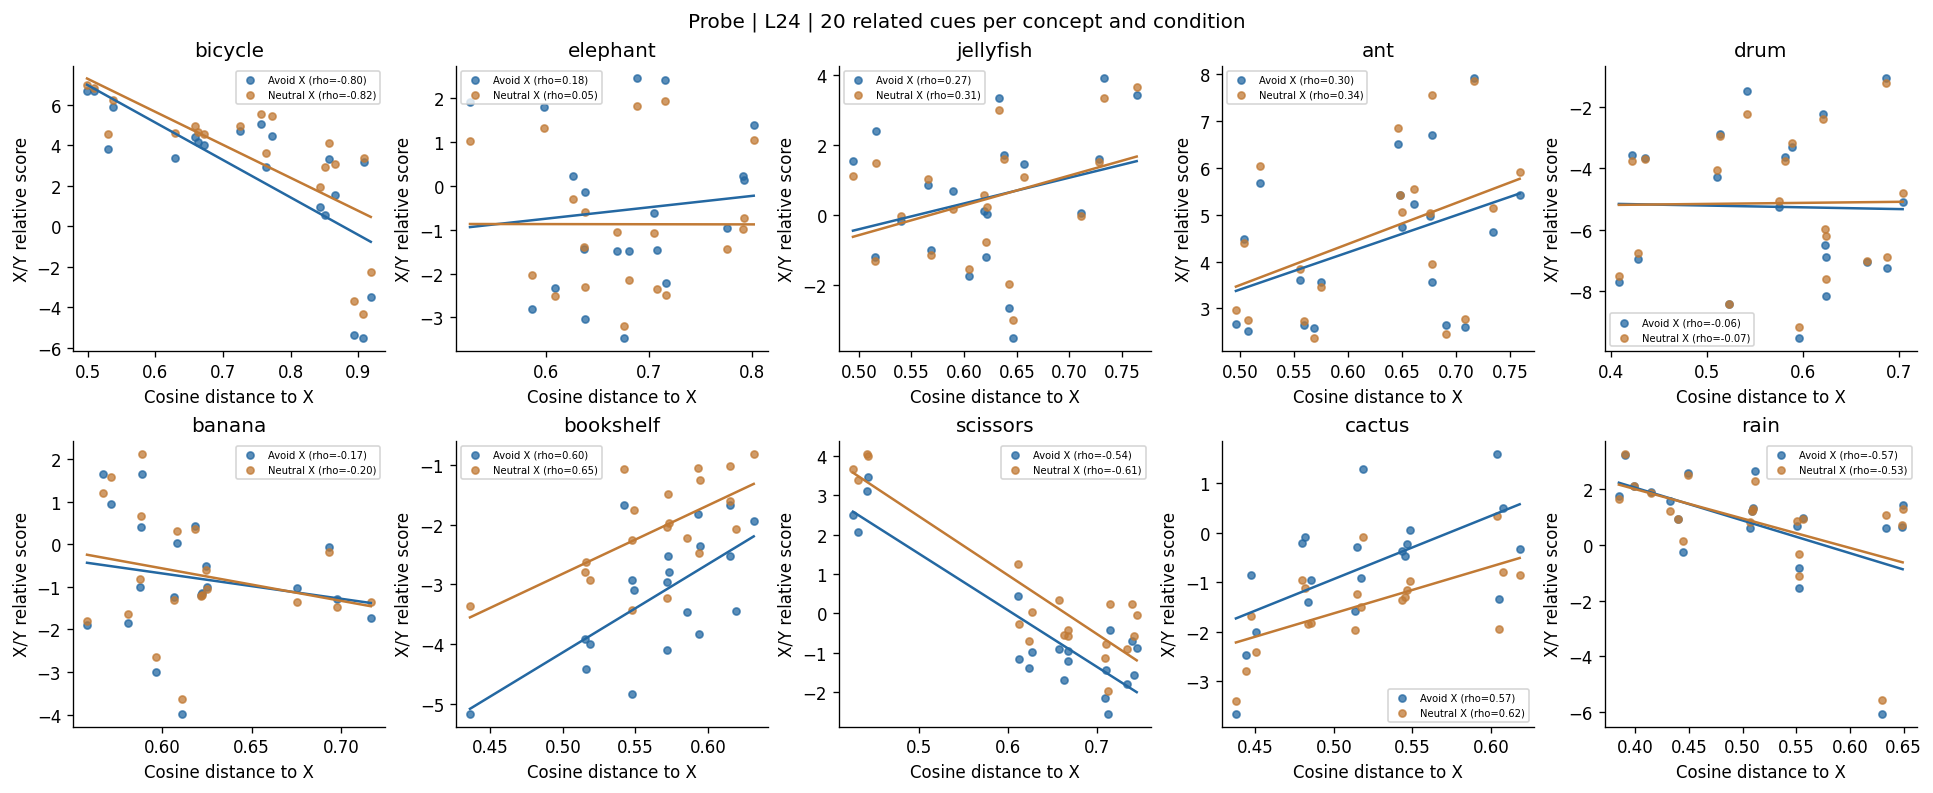

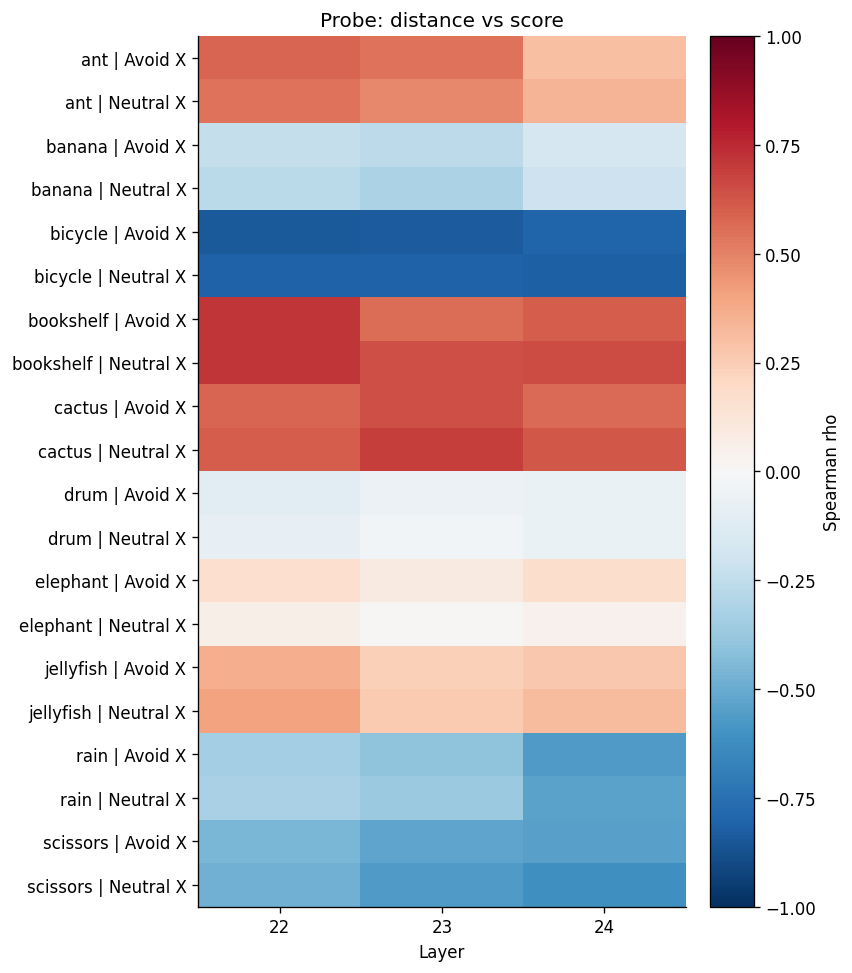

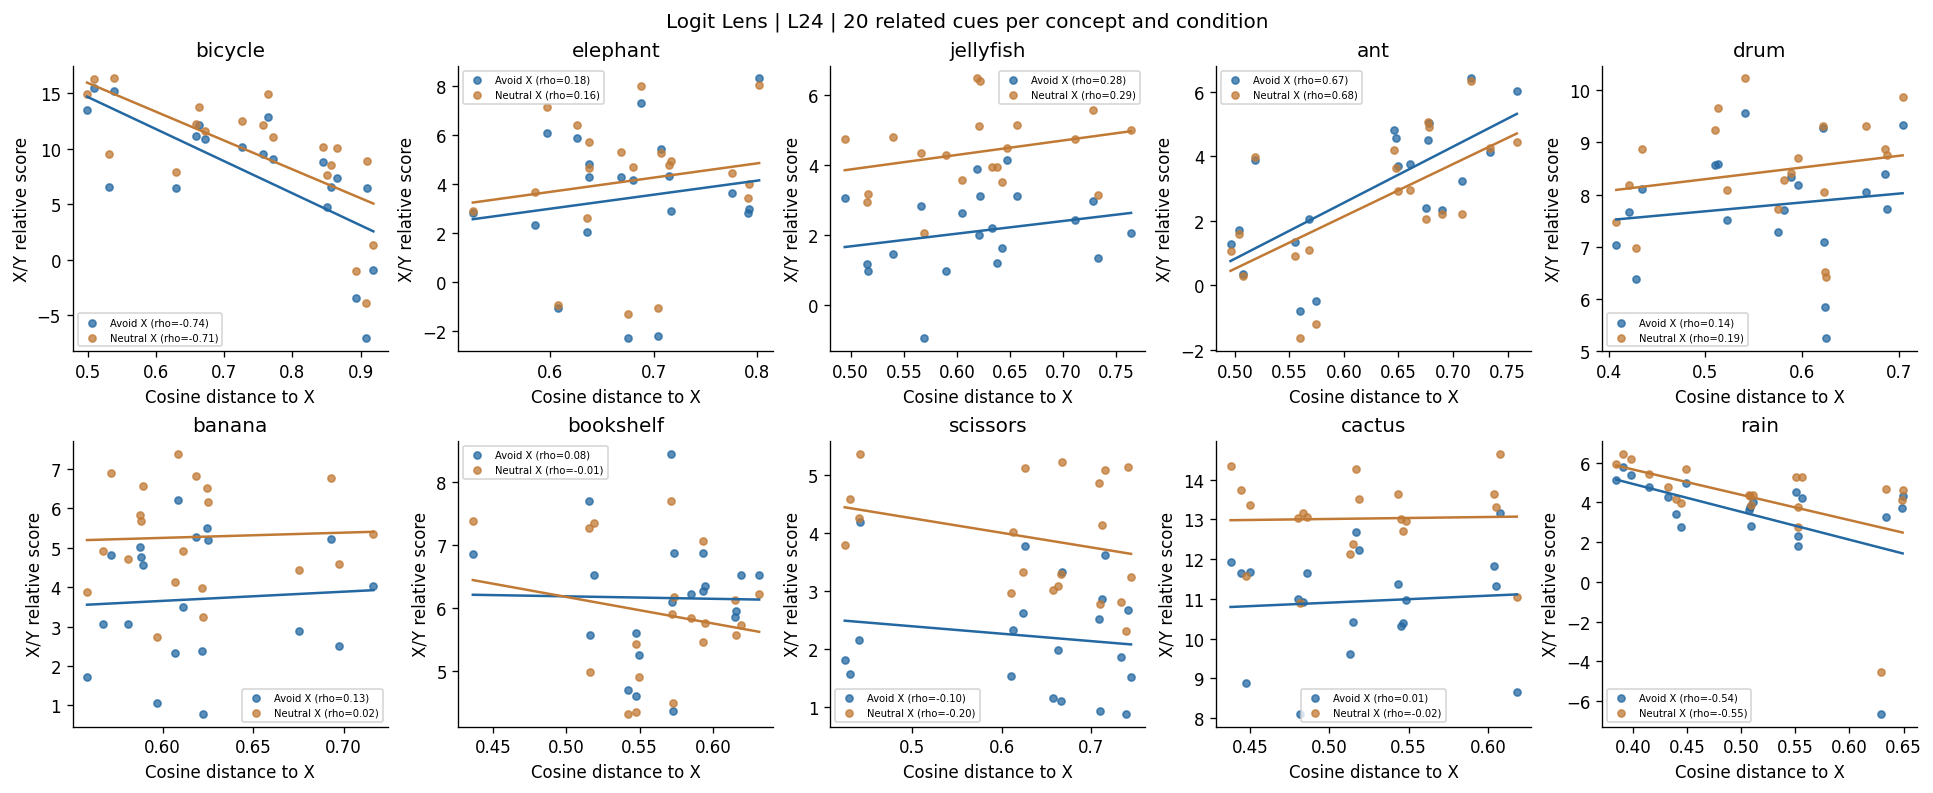

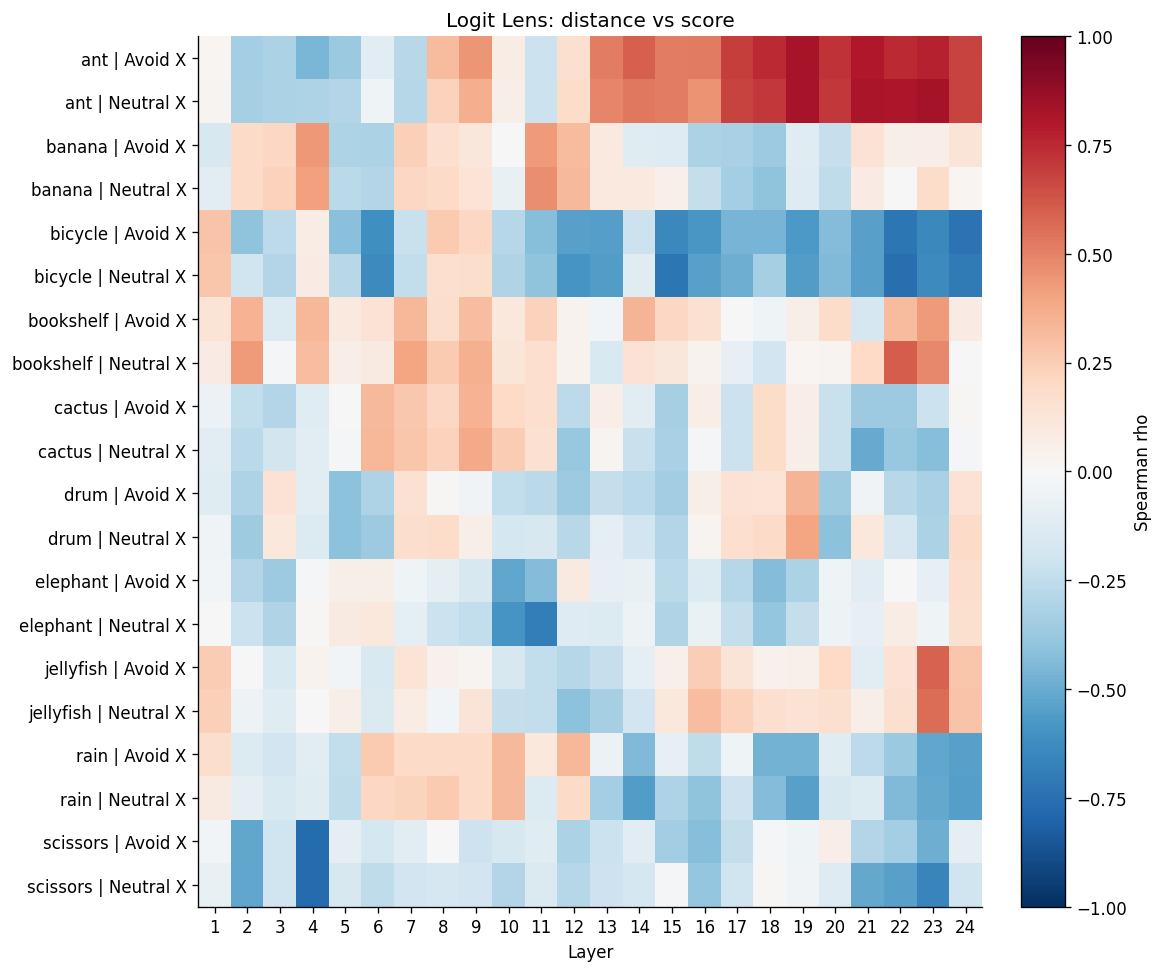

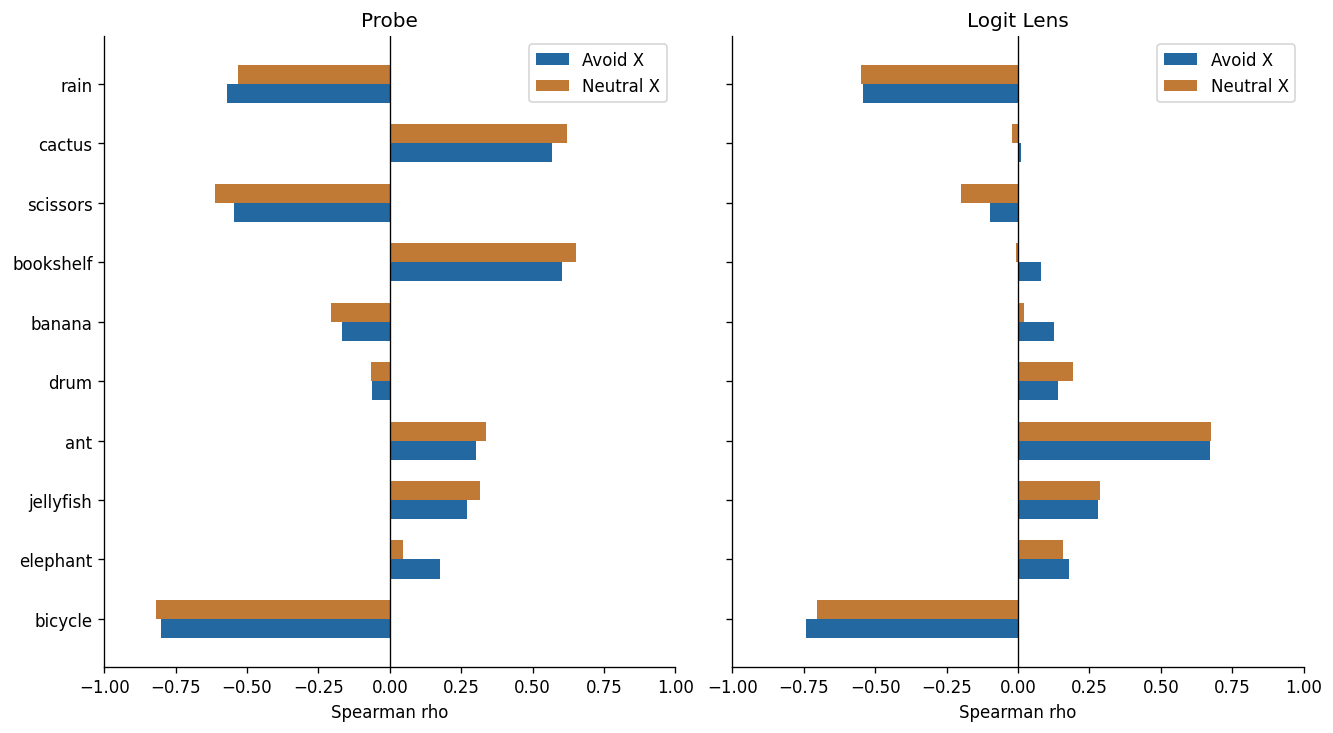

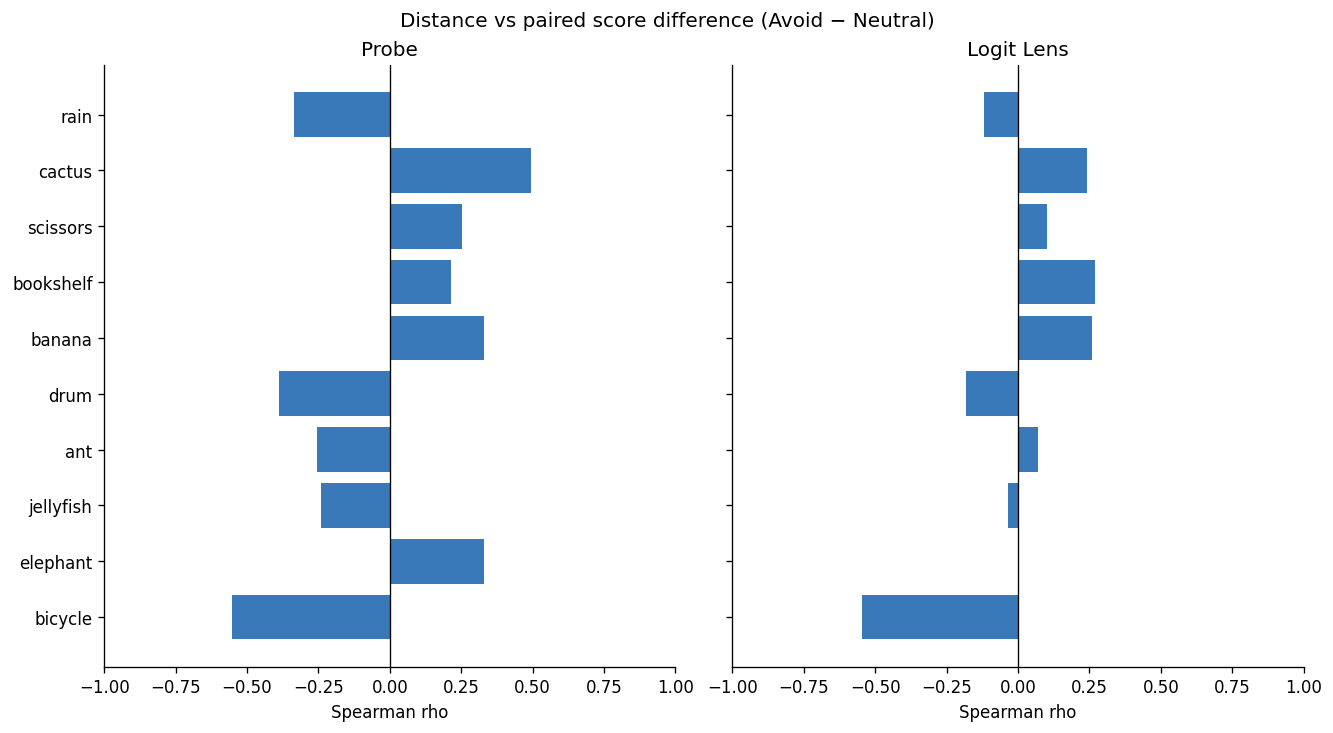

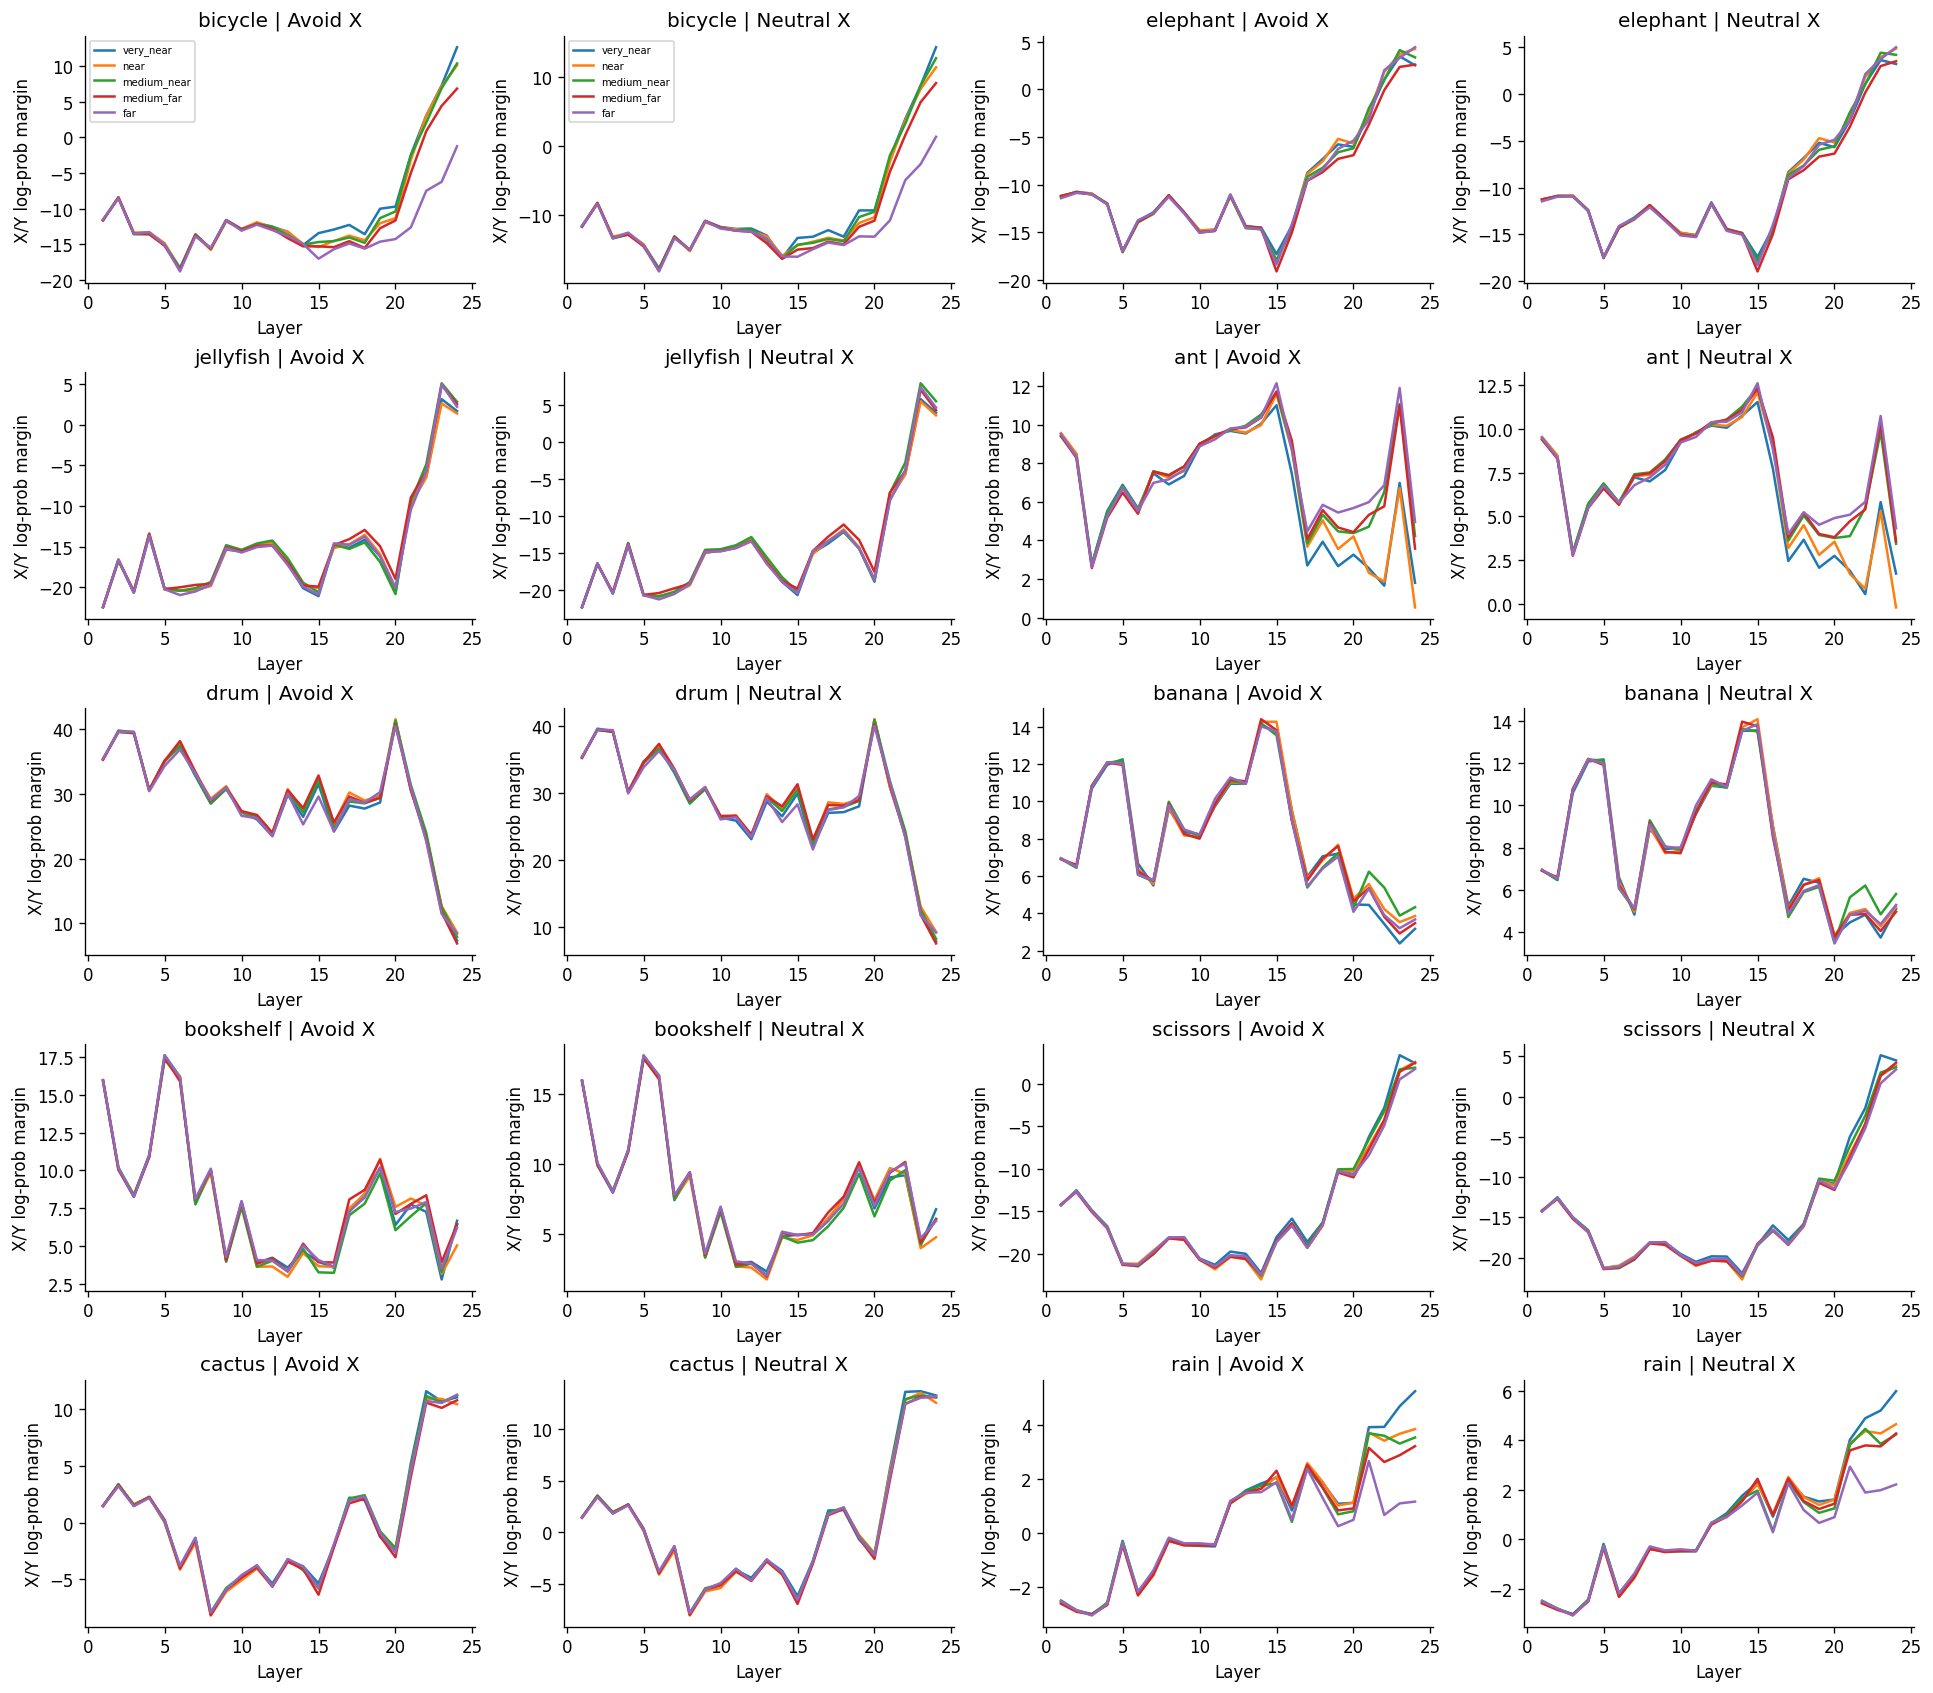

In [15]:
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
colors={"Avoid X":"#2468a2","Neutral X":"#c17a35"}
targets=pairs.target_x.tolist()
def plot_save(fig,name):
    for ext in ["png","pdf"]:
        buf=io.BytesIO()
        kwargs={"dpi":200} if ext=="png" else {"metadata":{"CreationDate":None,"ModDate":None}}
        fig.savefig(buf,format=ext,bbox_inches="tight",**kwargs)
        # Figures are generated locally; existing immutable remote artifacts are reused.
        existing=get(f"{DEST}/{name}.{ext}") if PUBLISH else None
        if existing is None:save(f"{name}.{ext}",buf.getvalue())
        else:save(f"{name}.{ext}",existing,False)
    plt.show();plt.close(fig)
for metric in ["Probe","Logit Lens"]:
    fig,axes=plt.subplots(2,5,figsize=(16,6.5),layout="constrained")
    for ax,x in zip(axes.flat,targets):
        for cond in CONDS:
            g=related.query("metric==@metric and target_x==@x and condition==@cond and layer==24")
            s=summary.query("metric==@metric and target_x==@x and condition==@cond and layer==24").iloc[0]
            ax.scatter(g.distance_x,g.score,s=18,color=colors[cond],alpha=.75,label=f"{cond} (rho={s.spearman_rho:.2f})")
            xx=np.array([g.distance_x.min(),g.distance_x.max()])
            ax.plot(xx,s.intercept+s.slope*xx,color=colors[cond])
        ax.set(title=x,xlabel="Cosine distance to X",ylabel="X/Y relative score")
        ax.legend(fontsize=6)
    fig.suptitle(f"{metric} | L24 | 20 related cues per concept and condition")
    plot_save(fig,metric.lower().replace(" ","_")+"_distance_scatter")
    g=summary[summary.metric.eq(metric)].copy();g["row"]=g.target_x+" | "+g.condition
    a=g.pivot(index="row",columns="layer",values="spearman_rho")
    fig,ax=plt.subplots(figsize=(max(7,len(a.columns)*.4),8),layout="constrained")
    im=ax.imshow(a.to_numpy(),aspect="auto",vmin=-1,vmax=1,cmap="RdBu_r")
    ax.set_xticks(range(len(a.columns)),a.columns);ax.set_yticks(range(len(a.index)),a.index)
    ax.set(title=f"{metric}: distance vs score",xlabel="Layer")
    fig.colorbar(im,ax=ax,label="Spearman rho")
    plot_save(fig,metric.lower().replace(" ","_")+"_correlation_heatmap")
fig,axes=plt.subplots(1,2,figsize=(11,6),sharey=True,layout="constrained")
for ax,metric in zip(axes,["Probe","Logit Lens"]):
    for j,cond in enumerate(CONDS):
        a=summary.query("metric==@metric and condition==@cond and layer==24").set_index("target_x").reindex(targets)
        ax.barh(np.arange(10)+(j-.5)*.32,a.spearman_rho,height=.32,label=cond,color=colors[cond])
    ax.set_yticks(range(10),targets);ax.set(xlim=(-1,1),xlabel="Spearman rho",title=metric)
    ax.axvline(0,color="black",lw=.8);ax.legend()
plot_save(fig,"final_layer_concept_correlations")
fig,axes=plt.subplots(1,2,figsize=(11,6),sharey=True,layout="constrained")
for ax,metric in zip(axes,["Probe","Logit Lens"]):
    a=diff.query("metric==@metric and layer==24").set_index("target_x").reindex(targets)
    ax.barh(range(10),a.spearman_rho,color="#3978b9")
    ax.set_yticks(range(10),targets);ax.set(xlim=(-1,1),xlabel="Spearman rho",title=metric)
    ax.axvline(0,color="black",lw=.8)
fig.suptitle("Distance vs paired score difference (Avoid − Neutral)")
plot_save(fig,"paired_condition_distance_correlations")
fig,axes=plt.subplots(5,4,figsize=(16,14),layout="constrained")
for i,x in enumerate(targets):
    for j,cond in enumerate(CONDS):
        ax=axes.flat[2*i+j]
        g=related.query("metric=='Logit Lens' and target_x==@x and condition==@cond")
        for band in BANDS:
            a=g[g.distance_band.eq(band)].groupby("layer").score.mean()
            ax.plot(a.index,a.values,label=band)
        ax.set(title=f"{x} | {cond}",xlabel="Layer",ylabel="X/Y log-prob margin")
        if i==0:ax.legend(fontsize=6)
plot_save(fig,"logit_lens_by_distance_band")



## 5. 報告・再現性
実験完了時のみmanifestを作成する。今回の10組は探索的な部分集合であり、50組の代表無作為標本ではない。



In [16]:
report=[
 "# Pre-main experiment — exploratory",
 f"- Run: {RUN_ID}",f"- Source: {SOURCE_SHA}",
 "- 10 fixed X/Y pairs, 10 categories; 240 cues; 500 prompts; 500 single generations.",
 "- 20 related cues per concept and condition; unrelated and no-cue excluded from distance regression.",
 "- Probe L22/23/24 restored from v5 cached training features, AUC matched on its independent text set.",
 "- Cue distance bands are within-concept empirical quintiles; not common numerical cutoffs.",
 "- AI-generated cues and prewritten definitions, no independent human audit. Style imbalance is logged in cue_quality.csv.",
 "- Probe scores are relative X/Y information; Lens margins are teacher-forced candidate sequence log probabilities.",
 "- No claim of thought quantity, causal suppression, or confirmatory significance.",
 "", "## Final-layer results", "",summary.query("layer==24").round(3).to_markdown(index=False),
 "", "## Paired slope difference", "",diff.query("layer==24").round(3).to_markdown(index=False),
 "", "## L22 exploratory follow-up", "",summary.query("layer==22 and condition=='Avoid X'").round(3).to_markdown(index=False),
 "", "## Generation quality",
 f"- Empty: {int(generations.empty_response.sum())}; truncation: {int(generations.truncated_at_limit.sum())}",
 "- Explicit mention is surface matching only; one generation per input is a supplemental outcome."
]
save("analysis_summary.md",("\n".join(report)+"\n").encode())
manifest=dict(status="COMPLETED_EXPLORATORY_PRE_MAIN_HUMAN_REVIEW_PENDING",config=config,
    prompt_sha256=PROMPT_HASH,cue_sha256=sha((WORK/"cue_selected.csv").read_bytes()),
    n_concepts=10,n_cues=240,n_inputs=500,n_probe=1500,n_lens=24000,n_outputs=500,
    max_native_error=max(r["native_error"] for r in all_results),
    torch_version=str(torch.__version__),gpu=torch.cuda.get_device_name(0),
    artifact_sha256={str(p.relative_to(WORK)):sha(p.read_bytes()) for p in sorted(WORK.rglob("*"))
                    if p.is_file() and p.name!="manifest.json"})
old=get(f"{DEST}/manifest.json") if PUBLISH else None
if old is not None:
    prior=json.loads(old)
    assert prior["prompt_sha256"]==PROMPT_HASH and prior["artifact_sha256"]==manifest["artifact_sha256"],"Existing completed run differs"
    save("manifest.json",old,False)
else:save("manifest.json",dump(manifest))
display(Markdown("\n".join(report)))
print("Saved:",f"https://github.com/{REPO}/tree/main/{DEST}")



# Pre-main experiment — exploratory
- Run: 20261124_pre_main_v1
- Source: a9095b153ff869556bcf3fbba4dddee6a43b305a
- 10 fixed X/Y pairs, 10 categories; 240 cues; 500 prompts; 500 single generations.
- 20 related cues per concept and condition; unrelated and no-cue excluded from distance regression.
- Probe L22/23/24 restored from v5 cached training features, AUC matched on its independent text set.
- Cue distance bands are within-concept empirical quintiles; not common numerical cutoffs.
- AI-generated cues and prewritten definitions, no independent human audit. Style imbalance is logged in cue_quality.csv.
- Probe scores are relative X/Y information; Lens margins are teacher-forced candidate sequence log probabilities.
- No claim of thought quantity, causal suppression, or confirmatory significance.

## Final-layer results

| metric     | target_x   | condition   |   layer |   n |   slope |   intercept |   pearson_r |   spearman_rho |
|:-----------|:-----------|:------------|--------:|----:|--------:|------------:|------------:|---------------:|
| Logit Lens | ant        | Avoid X     |      24 |  20 |  17.383 |      -7.871 |       0.708 |          0.672 |
| Logit Lens | ant        | Neutral X   |      24 |  20 |  16.226 |      -7.602 |       0.641 |          0.677 |
| Logit Lens | banana     | Avoid X     |      24 |  20 |   2.331 |       2.252 |       0.066 |          0.126 |
| Logit Lens | banana     | Neutral X   |      24 |  20 |   1.327 |       4.45  |       0.045 |          0.021 |
| Logit Lens | bicycle    | Avoid X     |      24 |  20 | -28.932 |      29.146 |      -0.704 |         -0.741 |
| Logit Lens | bicycle    | Neutral X   |      24 |  20 | -25.984 |      28.943 |      -0.685 |         -0.705 |
| Logit Lens | bookshelf  | Avoid X     |      24 |  20 |  -0.393 |       6.38  |      -0.018 |          0.08  |
| Logit Lens | bookshelf  | Neutral X   |      24 |  20 |  -4.222 |       8.284 |      -0.188 |         -0.008 |
| Logit Lens | cactus     | Avoid X     |      24 |  20 |   1.752 |      10.027 |       0.076 |          0.009 |
| Logit Lens | cactus     | Neutral X   |      24 |  20 |   0.497 |      12.761 |       0.028 |         -0.021 |
| Logit Lens | drum       | Avoid X     |      24 |  20 |   1.698 |       6.829 |       0.141 |          0.141 |
| Logit Lens | drum       | Neutral X   |      24 |  20 |   2.239 |       7.176 |       0.197 |          0.192 |
| Logit Lens | elephant   | Avoid X     |      24 |  20 |   5.749 |      -0.465 |       0.153 |          0.179 |
| Logit Lens | elephant   | Neutral X   |      24 |  20 |   5.845 |       0.165 |       0.162 |          0.156 |
| Logit Lens | jellyfish  | Avoid X     |      24 |  20 |   3.617 |      -0.121 |       0.228 |          0.281 |
| Logit Lens | jellyfish  | Neutral X   |      24 |  20 |   4.134 |       1.817 |       0.277 |          0.287 |
| Logit Lens | rain       | Avoid X     |      24 |  20 | -14.042 |      10.547 |      -0.477 |         -0.543 |
| Logit Lens | rain       | Neutral X   |      24 |  20 | -12.74  |      10.751 |      -0.493 |         -0.549 |
| Logit Lens | scissors   | Avoid X     |      24 |  20 |  -1.281 |       3.031 |      -0.146 |         -0.096 |
| Logit Lens | scissors   | Neutral X   |      24 |  20 |  -2.514 |       5.508 |      -0.283 |         -0.198 |
| Probe      | ant        | Avoid X     |      24 |  20 |   7.929 |      -0.56  |       0.414 |          0.302 |
| Probe      | ant        | Neutral X   |      24 |  20 |   8.771 |      -0.886 |       0.427 |          0.337 |
| Probe      | banana     | Avoid X     |      24 |  20 |  -5.972 |       2.898 |      -0.188 |         -0.167 |
| Probe      | banana     | Neutral X   |      24 |  20 |  -7.647 |       4.022 |      -0.242 |         -0.205 |
| Probe      | bicycle    | Avoid X     |      24 |  20 | -18.5   |      16.228 |      -0.741 |         -0.802 |
| Probe      | bicycle    | Neutral X   |      24 |  20 | -16.307 |      15.443 |      -0.726 |         -0.818 |
| Probe      | bookshelf  | Avoid X     |      24 |  20 |  14.806 |     -11.543 |       0.655 |          0.605 |
| Probe      | bookshelf  | Neutral X   |      24 |  20 |  11.461 |      -8.55  |       0.646 |          0.651 |
| Probe      | cactus     | Avoid X     |      24 |  20 |  12.773 |      -7.325 |       0.606 |          0.568 |
| Probe      | cactus     | Neutral X   |      24 |  20 |   9.451 |      -6.357 |       0.633 |          0.62  |
| Probe      | drum       | Avoid X     |      24 |  20 |  -0.576 |      -4.927 |      -0.022 |         -0.063 |
| Probe      | drum       | Neutral X   |      24 |  20 |   0.343 |      -5.333 |       0.014 |         -0.066 |
| Probe      | elephant   | Avoid X     |      24 |  20 |   2.592 |      -2.305 |       0.105 |          0.177 |
| Probe      | elephant   | Neutral X   |      24 |  20 |  -0.033 |      -0.854 |      -0.002 |          0.045 |
| Probe      | jellyfish  | Avoid X     |      24 |  20 |   7.386 |      -4.104 |       0.275 |          0.269 |
| Probe      | jellyfish  | Neutral X   |      24 |  20 |   8.525 |      -4.843 |       0.362 |          0.314 |
| Probe      | rain       | Avoid X     |      24 |  20 | -11.711 |       6.723 |      -0.521 |         -0.57  |
| Probe      | rain       | Neutral X   |      24 |  20 | -10.523 |       6.198 |      -0.514 |         -0.532 |
| Probe      | scissors   | Avoid X     |      24 |  20 | -14.349 |       8.681 |      -0.896 |         -0.544 |
| Probe      | scissors   | Neutral X   |      24 |  20 | -14.92  |       9.913 |      -0.905 |         -0.611 |

## Paired slope difference

| metric     | target_x   |   layer |   n |   slope |   intercept |   pearson_r |   spearman_rho |
|:-----------|:-----------|--------:|----:|--------:|------------:|------------:|---------------:|
| Logit Lens | ant        |      24 |  20 |   1.157 |      -0.269 |       0.189 |          0.069 |
| Logit Lens | banana     |      24 |  20 |   1.004 |      -2.199 |       0.099 |          0.259 |
| Logit Lens | bicycle    |      24 |  20 |  -2.947 |       0.203 |      -0.57  |         -0.544 |
| Logit Lens | bookshelf  |      24 |  20 |   3.829 |      -1.904 |       0.396 |          0.269 |
| Logit Lens | cactus     |      24 |  20 |   1.254 |      -2.734 |       0.163 |          0.242 |
| Logit Lens | drum       |      24 |  20 |  -0.541 |      -0.347 |      -0.156 |         -0.18  |
| Logit Lens | elephant   |      24 |  20 |  -0.096 |      -0.63  |      -0.013 |          0     |
| Logit Lens | jellyfish  |      24 |  20 |  -0.517 |      -1.938 |      -0.047 |         -0.036 |
| Logit Lens | rain       |      24 |  20 |  -1.303 |      -0.204 |      -0.267 |         -0.117 |
| Logit Lens | scissors   |      24 |  20 |   1.233 |      -2.477 |       0.243 |          0.101 |
| Probe      | ant        |      24 |  20 |  -0.842 |       0.326 |      -0.262 |         -0.254 |
| Probe      | banana     |      24 |  20 |   1.675 |      -1.124 |       0.271 |          0.329 |
| Probe      | bicycle    |      24 |  20 |  -2.193 |       0.785 |      -0.551 |         -0.552 |
| Probe      | bookshelf  |      24 |  20 |   3.345 |      -2.993 |       0.45  |          0.214 |
| Probe      | cactus     |      24 |  20 |   3.322 |      -0.968 |       0.49  |          0.493 |
| Probe      | drum       |      24 |  20 |  -0.919 |       0.406 |      -0.263 |         -0.389 |
| Probe      | elephant   |      24 |  20 |   2.625 |      -1.451 |       0.365 |          0.331 |
| Probe      | jellyfish  |      24 |  20 |  -1.139 |       0.739 |      -0.205 |         -0.239 |
| Probe      | rain       |      24 |  20 |  -1.188 |       0.525 |      -0.404 |         -0.334 |
| Probe      | scissors   |      24 |  20 |   0.571 |      -1.232 |       0.258 |          0.253 |

## L22 exploratory follow-up

| metric     | target_x   | condition   |   layer |   n |   slope |   intercept |   pearson_r |   spearman_rho |
|:-----------|:-----------|:------------|--------:|----:|--------:|------------:|------------:|---------------:|
| Logit Lens | ant        | Avoid X     |      22 |  20 |  26.853 |     -12.285 |       0.856 |          0.743 |
| Logit Lens | banana     | Avoid X     |      22 |  20 |   0.399 |       3.899 |       0.014 |          0.062 |
| Logit Lens | bicycle    | Avoid X     |      22 |  20 | -20.862 |      15.731 |      -0.619 |         -0.726 |
| Logit Lens | bookshelf  | Avoid X     |      22 |  20 |   6.649 |       4.045 |       0.333 |          0.316 |
| Logit Lens | cactus     | Avoid X     |      22 |  20 |  -5.088 |      13.616 |      -0.311 |         -0.361 |
| Logit Lens | drum       | Avoid X     |      22 |  20 |  -2.691 |      24.81  |      -0.197 |         -0.281 |
| Logit Lens | elephant   | Avoid X     |      22 |  20 |   2.176 |      -0.317 |       0.081 |          0     |
| Logit Lens | jellyfish  | Avoid X     |      22 |  20 |   3.905 |      -8.253 |       0.189 |          0.143 |
| Logit Lens | rain       | Avoid X     |      22 |  20 | -11.603 |       8.752 |      -0.393 |         -0.371 |
| Logit Lens | scissors   | Avoid X     |      22 |  20 |  -5.402 |      -0.462 |      -0.41  |         -0.343 |
| Probe      | ant        | Avoid X     |      22 |  20 |  27.109 |     -12.096 |       0.665 |          0.579 |
| Probe      | banana     | Avoid X     |      22 |  20 | -18.575 |       3.237 |      -0.282 |         -0.242 |
| Probe      | bicycle    | Avoid X     |      22 |  20 | -29.219 |      24.865 |      -0.757 |         -0.836 |
| Probe      | bookshelf  | Avoid X     |      22 |  20 |  23.131 |     -16.281 |       0.706 |          0.716 |
| Probe      | cactus     | Avoid X     |      22 |  20 |  21.166 |     -10.911 |       0.582 |          0.582 |
| Probe      | drum       | Avoid X     |      22 |  20 |  -1.025 |      -1.572 |      -0.029 |         -0.114 |
| Probe      | elephant   | Avoid X     |      22 |  20 |  10.459 |     -12.271 |       0.198 |          0.167 |
| Probe      | jellyfish  | Avoid X     |      22 |  20 |  12.555 |      -9.953 |       0.346 |          0.359 |
| Probe      | rain       | Avoid X     |      22 |  20 | -17.58  |       7.089 |      -0.392 |         -0.341 |
| Probe      | scissors   | Avoid X     |      22 |  20 | -26.086 |      12.265 |      -0.869 |         -0.454 |

## Generation quality
- Empty: 0; truncation: 0
- Explicit mention is surface matching only; one generation per input is a supplemental outcome.

Saved: https://github.com/ryouy/GraduationThesis/tree/main/experiments/2026-11/1124_pre_main_experiment/results/20261124_pre_main_v1
